In [131]:
import numpy as np
import math as mp
import pandas as pd
import matplotlib.pyplot as plt

kwargs = {
    "tau" : 5.783,
    "mu_f" : -4.0,
    "sigma_f" : 1.85,
    "alpha_f" : 5.85
}

def norm( t_incub, ** kwargs ) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]

    norm_const = sigma_f / alpha_f * ((1. + (t_incub/tau - 1.) * mp.pow(1. + mp.exp(mu_f / sigma_f), - alpha_f)) 
                                      - t_incub / tau * mp.pow(1. + mp.exp((mu_f + tau)/sigma_f), -alpha_f))
    return norm_const

def skew_logisitic_pdf(tost, t_incub, ** kwargs ) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]


    if tost <= 0 :
        x = tost * tau / t_incub
    else :
        x = tost
    y = mp.exp((mu_f - x) / sigma_f) * mp.pow(1. + mp.exp((mu_f - x) / sigma_f), - alpha_f - 1.)
    
    return y / norm(t_incub, ** kwargs)

def skew_logisitic_cdf(tost, t_incub, thomas=False, ** kwargs) :
    tau = kwargs["tau"]
    mu_f = kwargs["mu_f"]
    sigma_f = kwargs["sigma_f"]
    alpha_f = kwargs["alpha_f"]

    if tost <= 0 :
        y = t_incub / tau * (mp.pow(1. + mp.exp((mu_f - tost[tost <= 0] * tau / t_incub) / sigma_f), -alpha_f) - mp.pow(1. + mp.exp((mu_f + tau) / sigma_f), -alpha_f))
    else :
        tmp = t_incub / tau * (mp.pow(1. + mp.exp(mu_f / sigma_f), -alpha_f) - mp.power(1. + mp.exp((mu_f + tau) / sigma_f), -alpha_f))
        y = tmp + mp.power(1. + mp.exp((mu_f - tost[tost > 0]) / sigma_f), -alpha_f) - mp.power(1. + mp.exp(mu_f / sigma_f), -alpha_f)

    return y * sigma_f / (alpha_f * norm(t_incub, thomas=thomas, ** kwargs))

# Assesing Update of Infectivity Profile
In order to check if the simulation was updating correctly the infectivity profiels, I reproduced the same stochastic process of the cpp script, starting from the same randomnumber generators. Since the discretization returns the same bernoulli probability of infection at each time interval, I can believe that the cpp simulation is correct.

In [179]:
file_name = "dummy-proba-train.txt"
df = pd.read_csv(file_name, sep=" ", header=None, names=["indiv", "time", "u", "proba"])

delta_t = 0.01

df_HH = pd.read_csv("../output/simulated.txt", sep=" ", dtype=np.float64)
alpha = 0.001
beta = 1.2

study_period = df_HH["study_period"].max()

first_case = df_HH.at[ np.argmin(df_HH["onset_time"] - df_HH["incub_period"]), "index"]
infec_time = (df_HH["onset_time"] - df_HH["incub_period"]).min()
df_HH.set_index("index", drop=True, inplace=True)
beta_frac = beta / len(df_HH)

df_HH.loc[df_HH.index != first_case, "onset_time"] = 1000.

infectors = list([first_case])
sus = list(set(df_HH.index) - set(infectors))

store = { s : pd.DataFrame() for s in sus}

np.random.seed(22345)
for j, t in enumerate(np.arange(infec_time, study_period, delta_t)) :
    if len(sus) == 0 :
        break
    else :

        # loop over susceptible
        to_change = []
        for x, s in enumerate(sus):

            # compute risk of infection
            roi = alpha
            for i in infectors :
                tost = t + delta_t - df_HH.at[i, "onset_time"]
                t_incub = df_HH.at[i, "incub_period"]
                roi += beta_frac * skew_logisitic_pdf(tost, t_incub, ** kwargs)
            
            proba = 1. - np.exp(-roi * delta_t)
            store[s] = pd.concat([store[s], pd.DataFrame({"time" : [t], "proba" : [proba]})])

            u = df[df["indiv"] == s]["u"].values[j]
            #u = np.random.rand()

            if u < proba :
                to_change.append(s)

        for s in to_change :
            df_HH.at[s, "onset_time"] = t + delta_t + df_HH.at[s, "incub_period"]
            sus.remove(s)
            infectors.append(s)
df_HH

,status,HH_idx,HH_size,study_period,vacc_status,age,isol,sex,severity,vacc_delay,recov,incub_period,onset_time
index,,,,,,,,,,,,,
7.0,1.0,3.0,5.0,253.0,2.0,38.0,0.0,2.0,0.0,176.0,0.0,2.61842,232.00000
8.0,1.0,3.0,5.0,253.0,2.0,36.0,0.0,1.0,0.0,176.0,0.0,3.33553,236.23711
9.0,1.0,3.0,5.0,253.0,0.0,2.0,0.0,2.0,0.0,0.0,0.0,4.14617,235.11775
10.0,1.0,3.0,5.0,253.0,0.0,6.0,0.0,2.0,0.0,0.0,0.0,5.05810,236.09968
11.0,1.0,3.0,5.0,253.0,0.0,4.0,0.0,1.0,0.0,0.0,0.0,4.22709,241.12867


In [180]:
pd.read_csv("../output/simulated.txt", sep=" ", dtype=np.float64)

,index,status,HH_idx,HH_size,study_period,vacc_status,age,isol,sex,severity,vacc_delay,recov,incub_period,onset_time
0,7.0,1.0,3.0,5.0,253.0,2.0,38.0,0.0,2.0,0.0,176.0,0.0,2.61842,232.000
1,8.0,1.0,3.0,5.0,253.0,2.0,36.0,0.0,1.0,0.0,176.0,0.0,3.33553,236.237
2,9.0,1.0,3.0,5.0,253.0,0.0,2.0,0.0,2.0,0.0,0.0,0.0,4.14617,235.118
3,10.0,1.0,3.0,5.0,253.0,0.0,6.0,0.0,2.0,0.0,0.0,0.0,5.05810,236.100
4,11.0,1.0,3.0,5.0,253.0,0.0,4.0,0.0,1.0,0.0,0.0,0.0,4.22709,241.129


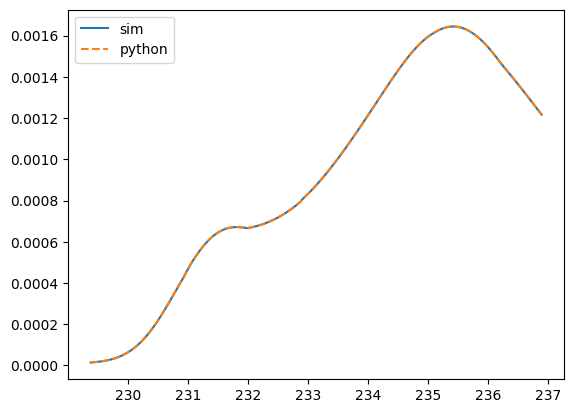

In [184]:
plt.figure()

indiv_idx = 11

sim = df[df["indiv"] == indiv_idx]["proba"]
plt.plot(df[df["indiv"] == indiv_idx]["time"], sim, label="sim")

plt.plot(store[indiv_idx]["time"], store[indiv_idx]["proba"], label="python", ls="--")
plt.legend()